# Lecture 22 — Newton's Method and IRLS

This notebook was created as complementary material for lecture 22: Newton's Method and IRLS. It is not a stand-alone notebook so please use it in conjunction with lecture 22. 

## Learning objectives

After using this notebook in parallel with lecture 22, you should be able to:

- implement Newton's method and iteratively reweighted least squares (IRLS) iteration for a simple logistic regression problem 
- experimentally compare its performance with the Gradient descent algorithm
- chance the code to explore the effect of learning rates and damping parameter on the convergence of the algorithms

In [ ]:
#### Imports #####
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit


In [ ]:
#### FUNCTIONS NEEDED #####

# --------------------------------------------------
# 2. Summed cross-entropy
# --------------------------------------------------

def cross_entropy(w):
    a = Phi @ w

    # Equivalent to:
    # -sum(t * log(y) + (1-t) * log(1-y))
    # but avoids taking log(0).
    return np.sum(np.logaddexp(0, a) - t * a)

# --------------------------------------------------
# 3. Gradient descent method 
# --------------------------------------------------
def fit_gradient_descent(eta=0.1, tolerance=1e-8, max_iterations=500):
    """Fit logistic regression using gradient descent."""
    w = np.zeros(Phi.shape[1])

    history = {
        "loss": [],
        "gradient_norm": [],
        "probability": [],
    }

    for iteration in range(max_iterations + 1):
        # Probabilities and gradient at the current weights
        y = expit(Phi @ w)
        gradient = Phi.T @ (y - t)
        gradient_norm = np.linalg.norm(gradient)

        # Record the current state
        history["loss"].append(cross_entropy(w))
        history["gradient_norm"].append(gradient_norm)
        history["probability"].append(expit(phi_day @ w))

        # Check stopping conditions
        if gradient_norm < tolerance:
            break

        if iteration == max_iterations:
            break

        # Gradient-descent update
        w = w - eta * gradient

    history = {
        key: np.asarray(values)
        for key, values in history.items()
    }

    converged = history["gradient_norm"][-1] < tolerance
    return w, history, converged

# --------------------------------------------------
# 4. Newton's method
# --------------------------------------------------
def fit_newton(tolerance=1e-8, max_iterations=500):
    """Fit logistic regression using Newton's method with backtracking."""
    w = np.zeros(Phi.shape[1])

    history = {
        "loss": [],
        "gradient_norm": [],
        "probability": [],
    }

    for iteration in range(max_iterations + 1):
        # Probabilities and gradient at the current weights
        y = expit(Phi @ w)
        gradient = Phi.T @ (y - t)
        gradient_norm = np.linalg.norm(gradient)
        loss = cross_entropy(w)

        # Record the current state
        history["loss"].append(loss)
        history["gradient_norm"].append(gradient_norm)
        history["probability"].append(expit(phi_day @ w))

        # Check stopping conditions
        if gradient_norm < tolerance:
            break

        if iteration == max_iterations:
            break

        # Hessian: H = Phi.T @ R @ Phi
        r = y * (1 - y)
        H = Phi.T @ (r[:, None] * Phi)

        # Newton direction: solve H @ direction = -gradient
        direction = np.linalg.solve(H, -gradient)

        # Start with a full step; shorten if necessary
        step = 1.0

        while cross_entropy(w + step * direction) > (
            loss + 1e-4 * step * (gradient @ direction)
        ):
            step *= 0.5

            if step < 1e-12:
                raise RuntimeError("Could not find a suitable Newton step.")

        # Newton update
        w = w + step * direction

    history = {
        key: np.asarray(values)
        for key, values in history.items()
    }

    converged = history["gradient_norm"][-1] < tolerance
    return w, history, converged

In [ ]:
# --------------------------------------------------
# Experimental implementation: Newton's method for logistic regression
# --------------------------------------------------
# 1. Illustrative observations
# --------------------------------------------------

# Columns: temperature (°C), occupancy (people).
# Each row is repeated for four observed days.
X = np.repeat(
    [
        [18, 30],
        [18, 80],
        [30, 30],
        [30, 80],
    ],
    repeats=4,
    axis=0,
)

# 0 = normal demand; 1 = high demand
t = np.array([
    0, 0, 0, 1,   # 18°C, 30 people
    0, 0, 1, 1,   # 18°C, 80 people
    0, 0, 1, 1,   # 30°C, 30 people
    0, 1, 1, 1,   # 30°C, 80 people
])

# Scaling the features, and adding the intercept column.
feature_mean = X.mean(axis=0)
feature_std = X.std(axis=0)

X_scaled = (X - feature_mean) / feature_std
Phi = np.column_stack((np.ones(len(t)), X_scaled))

# Track the probability for a fixed day.
selected_day = np.array([30, 80])
phi_day = np.r_[
    1.0,
    (selected_day - feature_mean) / feature_std,
]


In [ ]:
# --------------------------------------------------
# 2. Fit models using gradient descent and Newton's method
# --------------------------------------------------
w_gd, history_gd, converged_gd = fit_gradient_descent(eta=0.1)

w_newton, history_newton, converged_newton = fit_newton()
results = [
    ("Gradient descent", w_gd, history_gd, converged_gd),
    ("Newton", w_newton, history_newton, converged_newton),
]

for name, w, history, converged in results:
    print(f"\n{name}")
    print(f"  Converged: {converged}")
    print(f"  Updates: {len(history['loss']) - 1}")
    print(f"  Weights: {np.round(w, 4)}")
    print(f"  Cross-entropy: {history['loss'][-1]:.6f}")
    print(f"  Gradient norm: {history['gradient_norm'][-1]:.2e}")
    print(f"  Selected-day probability: {history['probability'][-1]:.3f}")




Gradient descent
  Converged: True
  Updates: 54
  Weights: [-0.      0.5493  0.5493]
  Cross-entropy: 10.043859
  Gradient norm: 7.34e-09
  Selected-day probability: 0.750

Newton
  Converged: True
  Updates: 4
  Weights: [-0.      0.5493  0.5493]
  Cross-entropy: 10.043859
  Gradient norm: 8.83e-13
  Selected-day probability: 0.750


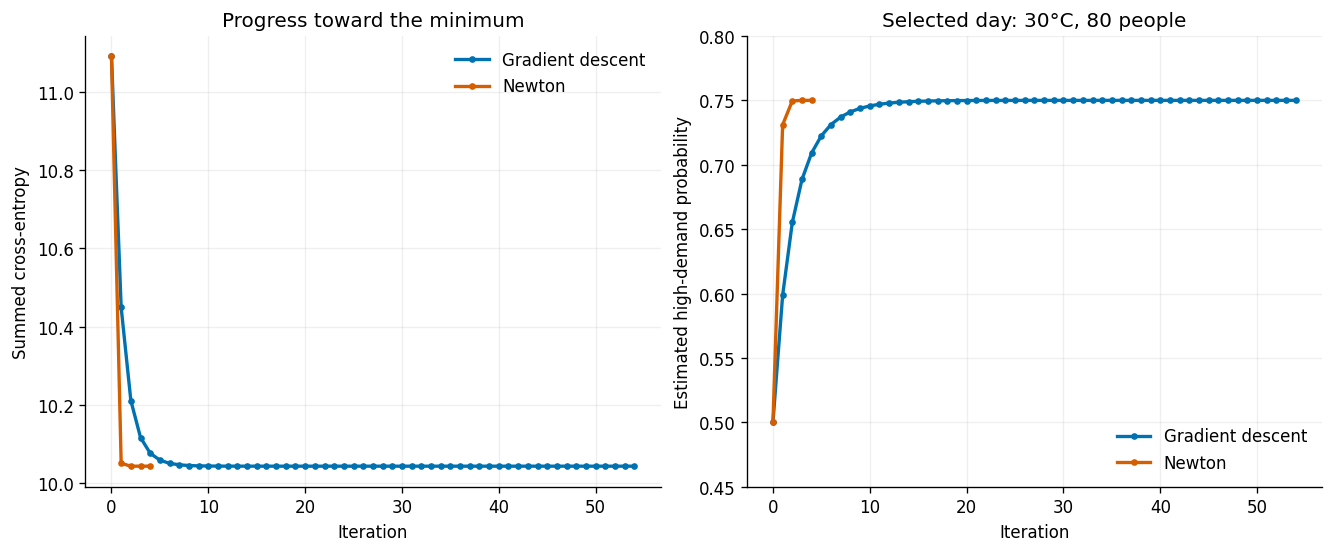

In [ ]:

# --------------------------------------------------
# 3. Plot the two histories for cross-entropy, and also the estimated high-demand probability for a particular day
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4.5),
    constrained_layout=True,
    dpi=120,
)

plot_settings = [
    ("Gradient descent", history_gd, "#0072B2"),
    ("Newton", history_newton, "#D55E00"),
]

for label, history, color in plot_settings:
    iterations = np.arange(len(history["loss"]))

    axes[0].plot(
        iterations,
        history["loss"],
        color=color,
        linewidth=2,
        marker=".",
        label=label,
    )

    axes[1].plot(
        iterations,
        history["probability"],
        color=color,
        linewidth=2,
        marker=".",
        label=label,
    )

axes[0].set_title("Progress toward the minimum")
axes[0].set_ylabel("Summed cross-entropy")

axes[1].set_title("Selected day: 30°C, 80 people")
axes[1].set_ylabel("Estimated high-demand probability")
axes[1].set_ylim(0.45, 0.80)

for ax in axes:
    ax.set_xlabel("Iteration")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)

plt.show()